In [44]:
import pandas as pd
import numpy as np
import os
import re
from plotnine import *
from eval_plot_utils import parse_yml_pred,output_evaluation_outputs

In [45]:
collected_data = []

In [ ]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_v2.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

In [53]:
tape_fintuned = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_test.csv').iloc[:,1:].drop_duplicates()

In [56]:
tape_fintuned.loc[tape_fintuned['substrate_seq']=='DHPYASLTLPDDAAA',:]

,kinase_seq,substrate_seq,label,prob,logit,predicted_label
1751,WLLSDILGQGATANVFRGRHKKTGDLFAIKVFNNISFLRPVDVQMR...,DHPYASLTLPDDAAA,1,0.803193,1.622841,1


## Evaluation on a subset of v2 data across multiple models - V2 Test

In [48]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_v2.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

In [4]:
pred_range = pd.read_csv('/ksi_ml/data/splits_v2/test.csv')
pred_range.columns = ['kinase_domain_seq','substrate_seq_15aa','label']

# pred_range = pd.read_csv('/ksi_ml/data/pairs_aug_v2_dark.csv').iloc[:,1:].drop_duplicates().loc[:,['kinase_domain_seq','substrate_seq_15aa','label']]

In [5]:
pairs_pred = pd.merge(pairs_pred,pred_range).drop_duplicates()

In [6]:
pairs_pred.head()

,kinase_seq,kinase_domain_seq,substrate_seq_15aa,label
0,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,PLLARSPSTNRKYPP,1
1,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,RRDYDDMSPRRGPPP,1
2,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,QRSRKRLSQDAYRRN,1
3,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,ENLKEKESCASRLCA,1
4,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,APIRRRSSNYRAYAT,1


In [7]:
phosphomer_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_v2.csv').iloc[:,1:]
phosphomer_pred = phosphomer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_pred.columns = ['kinase_seq','substrate_seq','probs']
phosphomer_pred.shape

(374257, 3)

In [8]:
kolossus_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_v2.csv').iloc[:,1:]
kolossus_pred = pd.merge(kolossus_pred,pairs_pred,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_pred.columns = ['kinase_seq','substrate_seq','probs']

In [9]:
tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__db_lysate__53ceb023016e.pkl').drop_duplicates()

In [46]:
tape_fintuned = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_test.csv').iloc[:,1:].drop_duplicates()
tape_fintuned = tape_fintuned.loc[:,['kinase_seq','substrate_seq','prob']].drop_duplicates()
tape_fintuned.columns = ['kinase_seq','substrate_seq','probs']

In [11]:
# pairs_pred should only be mutated after all the above code
pairs_pred = pairs_pred.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_pred.columns = ['kinase_seq', 'substrate_seq', 'label']

In [12]:
esmt12_noseq = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp3_esm2t12_unfrozen_v2__db_lysate__2b97b6229963.pkl').drop_duplicates()
# Dictionary to store prediction dataframes
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE-TUNED': tape_fintuned.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

pairs_pred = pairs_pred

In [13]:
# esm_db_lysate_pred_earlyloss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__db_lysate__a897476626a9.pkl').drop_duplicates()
#     'KINBERT:ESM_DB_Lysate-lossstop': esm_db_lysate_pred_earlyloss.drop_duplicates(['kinase_seq', 'substrate_seq']),

In [14]:

metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE-TUNED']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (33474, 3)

Initial shapes:
  Phosformer: (348847, 3)
  Kolossus: (33474, 3)
  KINBERT:TAPE: (348811, 3)
  KINBERT:TAPE-TUNED: (33474, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (33474, 4)
  Kolossus: aligned shape = (33474, 4)
  KINBERT:TAPE: aligned shape = (33474, 4)
  KINBERT:TAPE-TUNED: aligned shape = (33474, 4)

✓ All dataframes aligned to length: 33474

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0.5000):
  Accuracy:  0.6484
  Precision: 0.6453
  Recall:    0.3850
  F1 Score:  0.4823
  ROC-AUC:   0.6951
  PR-AUC:    0.6139
  MCC:       0.2594

Kolossus (threshold=0.5000):
  A

In [15]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.5,0.648354,0.645321,0.384972,0.482252,0.695053,0.613892,0.259399,0.843350,0.649385,5482,16221,3013,8758
1,Kolossus,0.5,0.689311,0.604189,0.781882,0.681646,0.778675,0.720274,0.400199,0.620776,0.793566,11134,11940,7294,3106
2,KINBERT:TAPE,0.5,0.922417,0.901123,0.918399,0.909679,0.973389,0.969992,0.841813,0.925393,0.938716,13078,17799,1435,1162
3,KINBERT:TAPE-TUNED,0.5,0.883880,0.827026,0.919312,0.870731,0.960102,0.953083,0.769397,0.857648,0.934882,13091,16496,2738,1149


In [16]:
p2 = p2+ scale_y_continuous(limits=(0, 1))

In [17]:
benchmark_id = 'eval_phosphopca_testv2'
# p2.save(f'./eval_figs/{benchmark_id}_bar.png')
# p4.save(f'./eval_figs/{benchmark_id}_roc.png')

In [18]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'DB + LYSATE Test'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")

✓ Collected eval_phosphopca_testv2 - Total: 1 benchmarks


## Evaluation on yeast-human dataset

In [41]:
pairs_yeast

,kinase_seq,substrate_seq,label
0,ITMKHKLGGGQYGEVYVGVWKKYSLTVAVKTLKEDTMEVEEFLKEA...,DSSYNHEYLGITGLP,1
1,ITMKHKLGGGQYGEVYVGVWKKYSLTVAVKTLKEDTMEVEEFLKEA...,AFRKVKQYIEPESVK,1
2,ITMKHKLGGGQYGEVYVGVWKKYSLTVAVKTLKEDTMEVEEFLKEA...,MDKLVVNYYEYKHPI,1
3,ITMKHKLGGGQYGEVYVGVWKKYSLTVAVKTLKEDTMEVEEFLKEA...,ISERKKLYSEYQKAK,1
4,ITMKHKLGGGQYGEVYVGVWKKYSLTVAVKTLKEDTMEVEEFLKEA...,IDLNKEVYDFLASAT,1
...,...,...,...
7058,LRLEVKLGQGCFGEVWMGTWNGTTKVAIKTLKPGTMMPEAFLQEAQ...,PPMRGFKYTSWSPMG,0
7059,LRLEVKLGQGCFGEVWMGTWNGTTKVAIKTLKPGTMMPEAFLQEAQ...,NCIGRRNYRYFFLFL,0
7060,LRLEVKLGQGCFGEVWMGTWNGTTKVAIKTLKPGTMMPEAFLQEAQ...,LNAQKAGYGAAVVHN,0
7061,LRLEVKLGQGCFGEVWMGTWNGTTKVAIKTLKPGTMMPEAFLQEAQ...,RKTKNIDYKKPLKVI,0


In [42]:
pairs_yeast = pd.read_csv('/ksi_ml/data/pairs_aug_yeast_fixed.csv').iloc[:,1:].drop_duplicates()
pairs_yeast = pairs_yeast.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

phosphomer_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_yeast.csv').iloc[:,1:]
phosphomer_yeast = phosphomer_yeast.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_yeast.columns = ['kinase_seq','substrate_seq','probs']

kolossus_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_yeast.csv').iloc[:,1:]
kolossus_yeast = pd.merge(kolossus_yeast,pairs_yeast,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_yeast.columns = ['kinase_seq','substrate_seq','probs']

tape_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__yeast_human__53ceb023016e.pkl').drop_duplicates()


tape_fintuned = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/finetune_tape_v2_phosphopca_exp6___pairs_aug_yeast.csv').iloc[:,1:].drop_duplicates()
tape_fintuned = tape_fintuned.loc[:,['kinase_domain_seq','substrate_seq_15aa','prob']].drop_duplicates()
tape_fintuned.columns = ['kinase_seq','substrate_seq','probs']

# pairs_yeast should only be mutated after all the above code
pairs_yeast = pairs_yeast.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_yeast.columns = ['kinase_seq', 'substrate_seq', 'label']

pairs_pred = pairs_yeast
prediction_dfs = {
    'Phosformer': phosphomer_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate': esm_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE-TUNED': tape_fintuned.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

benchmark_id = 'eval_yeast'

# collected_data.append({
#     'metrics': metrics_df.copy(),
#     'roc': p4.data.copy() if hasattr(p4, 'data') else None,
#     'benchmark_id': benchmark_id,
#     'test_name': 'Yeast x Human PK'  # CHANGE THIS FOR EACH BENCHMARK
# })
# print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")


KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE-TUNED']
Threshold mode: optimal

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (7061, 3)

Initial shapes:
  Phosformer: (7061, 3)
  Kolossus: (7061, 3)
  KINBERT:TAPE: (7061, 3)
  KINBERT:TAPE-TUNED: (7061, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (7061, 4)
  Kolossus: aligned shape = (7061, 4)
  KINBERT:TAPE: aligned shape = (7061, 4)
  KINBERT:TAPE-TUNED: aligned shape = (7061, 4)

✓ All dataframes aligned to length: 7061

[Step 2.5] Finding optimal F1-maximizing thresholds...
  Phosformer:
    Optimal threshold: 0.3314
    Max F1 score: 0.6706
  Kolossus:
    Optimal threshold: 0.3504
    Max F1 score: 0.6351
  KINBERT:TAPE:
    Optimal threshold: 0.0019
    Max F1 score: 0.6699
  KINBERT:TAPE-TUNED:
    Optimal threshold: 0.0082
    Max F1 score: 0.6547

[Step 3] Calculatin

In [43]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.331406,0.601615,0.538650,0.888337,0.670647,0.697188,0.606574,0.287640,0.360698,0.793578,2864,1384,2453,360
1,Kolossus,0.350447,0.541141,0.498586,0.874690,0.635135,0.636980,0.571282,0.169148,0.260881,0.712456,2820,1001,2836,404
2,KINBERT:TAPE,0.001864,0.600198,0.537624,0.888648,0.669940,0.714544,0.676596,0.285349,0.357832,0.792725,2865,1373,2464,359
3,KINBERT:TAPE-TUNED,0.008235,0.554029,0.506361,0.925868,0.654677,0.649571,0.595208,0.224658,0.241595,0.795026,2985,927,2910,239


## Evaluation on KSI screening dataset - phosphoPCA Train

In [20]:
pairs_yeast = pd.read_csv('/ksi_ml/data/pairs_aug_phosphopca_finetuning.csv').iloc[:,1:].drop_duplicates()
pairs_yeast = pairs_yeast.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]
pairs_train = pd.read_csv('/ksi_ml/data/splits_phosphopca_finetuning/train.csv').iloc[:,1:]
pairs_train.columns = ['kinase_domain_seq','substrate_seq_15aa','label']
pairs_yeast = pd.merge(pairs_yeast,pairs_train)

phosphomer_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_phosphopca_finetuning.csv').iloc[:,1:]
phosphomer_yeast = phosphomer_yeast.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_yeast.columns = ['kinase_seq','substrate_seq','probs']

kolossus_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_phosphopca_finetuning.csv').iloc[:,1:]
kolossus_yeast = pd.merge(kolossus_yeast,pairs_yeast,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_yeast.columns = ['kinase_seq','substrate_seq','probs']


tape_fintuned = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/finetune_tape_v2_phosphopca_exp6__pairs_aug_phosphopca_finetuning.csv').iloc[:,1:].drop_duplicates()
tape_fintuned = tape_fintuned.loc[:,['kinase_domain_seq','substrate_seq_15aa','prob']].drop_duplicates()
tape_fintuned.columns = ['kinase_seq','substrate_seq','probs']

tape_db_lysate = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__pairs_aug_phosphopca_finetuning.csv').iloc[:,1:].drop_duplicates()
tape_db_lysate = tape_db_lysate.loc[:,['kinase_domain_seq','substrate_seq_15aa','prob']].drop_duplicates()
tape_db_lysate.columns = ['kinase_seq','substrate_seq','probs']


# pairs_yeast should only be mutated after all the above code
pairs_yeast = pairs_yeast.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_yeast.columns = ['kinase_seq', 'substrate_seq', 'label']



In [21]:
pairs_yeast.groupby('label').count()

,kinase_seq,substrate_seq
label,,
0,5085,5085
1,4549,4549


In [22]:
pairs_pred = pairs_yeast
prediction_dfs = {
    'Phosformer': phosphomer_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate': esm_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE-TUNED': tape_fintuned.drop_duplicates(['kinase_seq', 'substrate_seq'])
    
}

In [23]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  # threshold_mode='fixed',
                                                  #  fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC']
                                                  )

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE-TUNED']
Threshold mode: optimal

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (9634, 3)

Initial shapes:
  Phosformer: (12066, 3)
  Kolossus: (9634, 3)
  KINBERT:TAPE: (12066, 3)
  KINBERT:TAPE-TUNED: (12066, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (9634, 4)
  Kolossus: aligned shape = (9634, 4)
  KINBERT:TAPE: aligned shape = (9634, 4)
  KINBERT:TAPE-TUNED: aligned shape = (9634, 4)

✓ All dataframes aligned to length: 9634

[Step 2.5] Finding optimal F1-maximizing thresholds...
  Phosformer:
    Optimal threshold: 0.0307
    Max F1 score: 0.6423
  Kolossus:
    Optimal threshold: 0.0000
    Max F1 score: 0.6415
  KINBERT:TAPE:
    Optimal threshold: 0.0020
    Max F1 score: 0.6778
  KINBERT:TAPE-TUNED:
    Optimal threshold: 0.4070
    Max F1 score: 0.8810

[Step 3] Calcula

In [24]:
benchmark_id = 'eval_phosphopca_train'

In [25]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'PhosphoPCA KSIs Train'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")

✓ Collected eval_phosphopca_train - Total: 2 benchmarks


In [26]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.030704,0.475088,0.473509,0.998022,0.642286,0.511370,0.546126,0.038367,0.007276,0.804348,4540,37,5048,9
1,Kolossus,0.000000,0.472182,0.472182,1.000000,0.641472,0.421265,0.437685,0.000000,0.000000,0.000000,4549,0,5085,0
2,KINBERT:TAPE,0.002038,0.569857,0.524359,0.958233,0.677811,0.604653,0.533892,0.262189,0.222419,0.856170,4359,1131,3954,190
3,KINBERT:TAPE-TUNED,0.406988,0.884368,0.856994,0.906353,0.880983,0.946066,0.929361,0.769859,0.864700,0.911673,4123,4397,688,426


## Evaluation on KSI screening dataset - phosphoPCA Test

In [27]:
pairs_yeast = pd.read_csv('/ksi_ml/data/pairs_aug_phosphopca_finetuning.csv').iloc[:,1:].drop_duplicates()
pairs_yeast = pairs_yeast.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]
pairs_train = pd.read_csv('/ksi_ml/data/splits_phosphopca_finetuning/test.csv').iloc[:,1:]
pairs_train.columns = ['kinase_domain_seq','substrate_seq_15aa','label']
pairs_yeast = pd.merge(pairs_yeast,pairs_train)

phosphomer_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_phosphopca_finetuning.csv').iloc[:,1:]
phosphomer_yeast = phosphomer_yeast.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_yeast.columns = ['kinase_seq','substrate_seq','probs']

kolossus_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_phosphopca_finetuning.csv').iloc[:,1:]
kolossus_yeast = pd.merge(kolossus_yeast,pairs_yeast,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_yeast.columns = ['kinase_seq','substrate_seq','probs']


tape_fintuned = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/finetune_tape_v2_phosphopca_exp6__pairs_aug_phosphopca_finetuning.csv').iloc[:,1:].drop_duplicates()
tape_fintuned = tape_fintuned.loc[:,['kinase_domain_seq','substrate_seq_15aa','prob']].drop_duplicates()
tape_fintuned.columns = ['kinase_seq','substrate_seq','probs']

tape_db_lysate = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__pairs_aug_phosphopca_finetuning.csv').iloc[:,1:].drop_duplicates()
tape_db_lysate = tape_db_lysate.loc[:,['kinase_domain_seq','substrate_seq_15aa','prob']].drop_duplicates()
tape_db_lysate.columns = ['kinase_seq','substrate_seq','probs']


# pairs_yeast should only be mutated after all the above code
pairs_yeast = pairs_yeast.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_yeast.columns = ['kinase_seq', 'substrate_seq', 'label']



In [28]:
pairs_yeast.groupby('label').count()

,kinase_seq,substrate_seq
label,,
0,624,624
1,560,560


In [29]:
pairs_pred = pairs_yeast
prediction_dfs = {
    'Phosformer': phosphomer_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate': esm_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE-TUNED': tape_fintuned.drop_duplicates(['kinase_seq', 'substrate_seq'])
    
}

In [30]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  # threshold_mode='fixed',
                                                  #  fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC']
                                                  )

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE-TUNED']
Threshold mode: optimal

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (1184, 3)

Initial shapes:
  Phosformer: (12066, 3)
  Kolossus: (1184, 3)
  KINBERT:TAPE: (12066, 3)
  KINBERT:TAPE-TUNED: (12066, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (1184, 4)
  Kolossus: aligned shape = (1184, 4)
  KINBERT:TAPE: aligned shape = (1184, 4)
  KINBERT:TAPE-TUNED: aligned shape = (1184, 4)

✓ All dataframes aligned to length: 1184

[Step 2.5] Finding optimal F1-maximizing thresholds...
  Phosformer:
    Optimal threshold: 0.0261
    Max F1 score: 0.6426
  Kolossus:
    Optimal threshold: 0.0000
    Max F1 score: 0.6422
  KINBERT:TAPE:
    Optimal threshold: 0.0030
    Max F1 score: 0.6728
  KINBERT:TAPE-TUNED:
    Optimal threshold: 0.2178
    Max F1 score: 0.7974

[Step 3] Calcula

In [31]:
benchmark_id = 'eval_phosphopca_test'

In [32]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'PhosphoPCA KSIs Test'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")

✓ Collected eval_phosphopca_test - Total: 3 benchmarks


In [33]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.026067,0.473818,0.473373,1.000000,0.642570,0.510252,0.552178,0.027543,0.001603,1.000000,560,1,623,0
1,Kolossus,0.000000,0.472973,0.472973,1.000000,0.642202,0.451588,0.469001,0.000000,0.000000,0.000000,560,0,624,0
2,KINBERT:TAPE,0.002955,0.576014,0.529774,0.921429,0.672751,0.610232,0.546872,0.245015,0.266026,0.790476,516,166,458,44
3,KINBERT:TAPE-TUNED,0.217839,0.787162,0.725146,0.885714,0.797428,0.863602,0.815892,0.590755,0.698718,0.872000,496,436,188,64


## Plotting for the collected statistics

In [34]:
import pandas as pd
from plotnine import *

print("="*80)
print(f"GENERATING COMBINED PLOTS FROM {len(collected_data)} BENCHMARKS")
print("="*80)

# Combine all data
all_metrics = []
all_roc = []

for data in collected_data:
    m = data['metrics'].copy()
    m['Test_Dataset'] = data['test_name']
    m['Benchmark_ID'] = data['benchmark_id']
    all_metrics.append(m)
    
    if data['roc'] is not None:
        r = data['roc'].copy()
        r['Test_Dataset'] = data['test_name']
        all_roc.append(r)

combined_metrics = pd.concat(all_metrics, ignore_index=True)
combined_roc = pd.concat(all_roc) if all_roc else None

print(f"\n✓ Combined data from {len(collected_data)} benchmarks")
print(f"  Test datasets: {combined_metrics['Test_Dataset'].unique()}")
print(f"  Models: {combined_metrics['Model'].unique()}")

# =============================================================================
# BARPLOT: ROC_AUC and PR_AUC
# =============================================================================

print("\nCreating barplot...")

df_long = combined_metrics[['Model', 'ROC_AUC', 'PR_AUC', 'Test_Dataset']].melt(
    id_vars=['Model', 'Test_Dataset'],
    var_name='Metric',
    value_name='Score'
)

models = df_long['Model'].unique()
colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', 
          '#1ABC9C', '#E91E63', '#FF5722', '#00BCD4', '#8BC34A']
model_colors = {m: colors[i % len(colors)] for i, m in enumerate(models)}

p_bar = (
    ggplot(df_long, aes(x='Metric', y='Score', fill='Model'))
    + geom_bar(stat='identity', position=position_dodge(0.8), width=0.7)
    + facet_wrap('~Test_Dataset', ncol=4)
    + theme_bw()
    + theme(
        axis_text_x=element_text(rotation=0, hjust=0.5, size=10),
        figure_size=(18, 7),
        legend_position='bottom',
        legend_title=element_text(size=11, face='bold'),
        strip_text=element_text(size=11, face='bold'),
        plot_title=element_text(size=14, face='bold')
    )
    + labs(
        title='Performance Metrics Comparison Across Test Datasets',
        x='Metric',
        y='Score',
        fill='Model'
    )
    + scale_fill_manual(values=model_colors)
    + geom_hline(yintercept=0.5, linetype='dashed', alpha=0.3)
    + scale_y_continuous(limits=(0, 1))
)


# =============================================================================
# ROC CURVES
# =============================================================================

if combined_roc is not None:
    print("Creating ROC curves...")
    
    p_roc = (
        ggplot(combined_roc, aes(x='FPR', y='TPR', color='Model'))
        + geom_line(size=1.2)
        + facet_wrap('~Test_Dataset', ncol=4)
        + geom_line(
            aes(x='FPR', y='FPR'), 
            color='gray', 
            linetype='dashed',
            data=pd.DataFrame({'FPR': [0, 1]}),
            inherit_aes=False
        )
        + theme_bw()
        + theme(
            figure_size=(18, 5),
            legend_position='bottom',
            strip_text=element_text(size=11, face='bold'),
            plot_title=element_text(size=14, face='bold')
        )
        + labs(
            title='ROC Curves Comparison Across Test Datasets',
            x='False Positive Rate',
            y='True Positive Rate',
            color='Model'
        )
        + scale_color_manual(values=model_colors)
    )
else:
    print("⚠ No ROC data collected")



# Summary statistics
print("\n" + "="*80)
print("SUMMARY")
print("="*80)

summary = df_long.groupby(['Test_Dataset', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by test dataset:")
print(summary)

model_summary = df_long.groupby(['Model', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by model (averaged across datasets):")
print(model_summary.sort_values('ROC_AUC', ascending=False))

print("\n" + "="*80)
print("COMPLETE!")
print("="*80)



GENERATING COMBINED PLOTS FROM 3 BENCHMARKS

✓ Combined data from 3 benchmarks
  Test datasets: ['DB + LYSATE Test' 'PhosphoPCA KSIs Train' 'PhosphoPCA KSIs Test']
  Models: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE-TUNED']
Categories (4, object): ['Phosformer' < 'Kolossus' < 'KINBERT:TAPE' < 'KINBERT:TAPE-TUNED']

Creating barplot...
Creating ROC curves...

SUMMARY

Mean scores by test dataset:
Metric                 PR_AUC  ROC_AUC
Test_Dataset                          
DB + LYSATE Test        0.814    0.852
PhosphoPCA KSIs Test    0.596    0.609
PhosphoPCA KSIs Train   0.612    0.621

Mean scores by model (averaged across datasets):
Metric              PR_AUC  ROC_AUC
Model                              
KINBERT:TAPE-TUNED   0.899    0.923
KINBERT:TAPE         0.684    0.729
Phosformer           0.571    0.572
Kolossus             0.542    0.551

COMPLETE!


In [35]:
summary

Metric,PR_AUC,ROC_AUC
Test_Dataset,,
DB + LYSATE Test,0.814,0.852
PhosphoPCA KSIs Test,0.596,0.609
PhosphoPCA KSIs Train,0.612,0.621


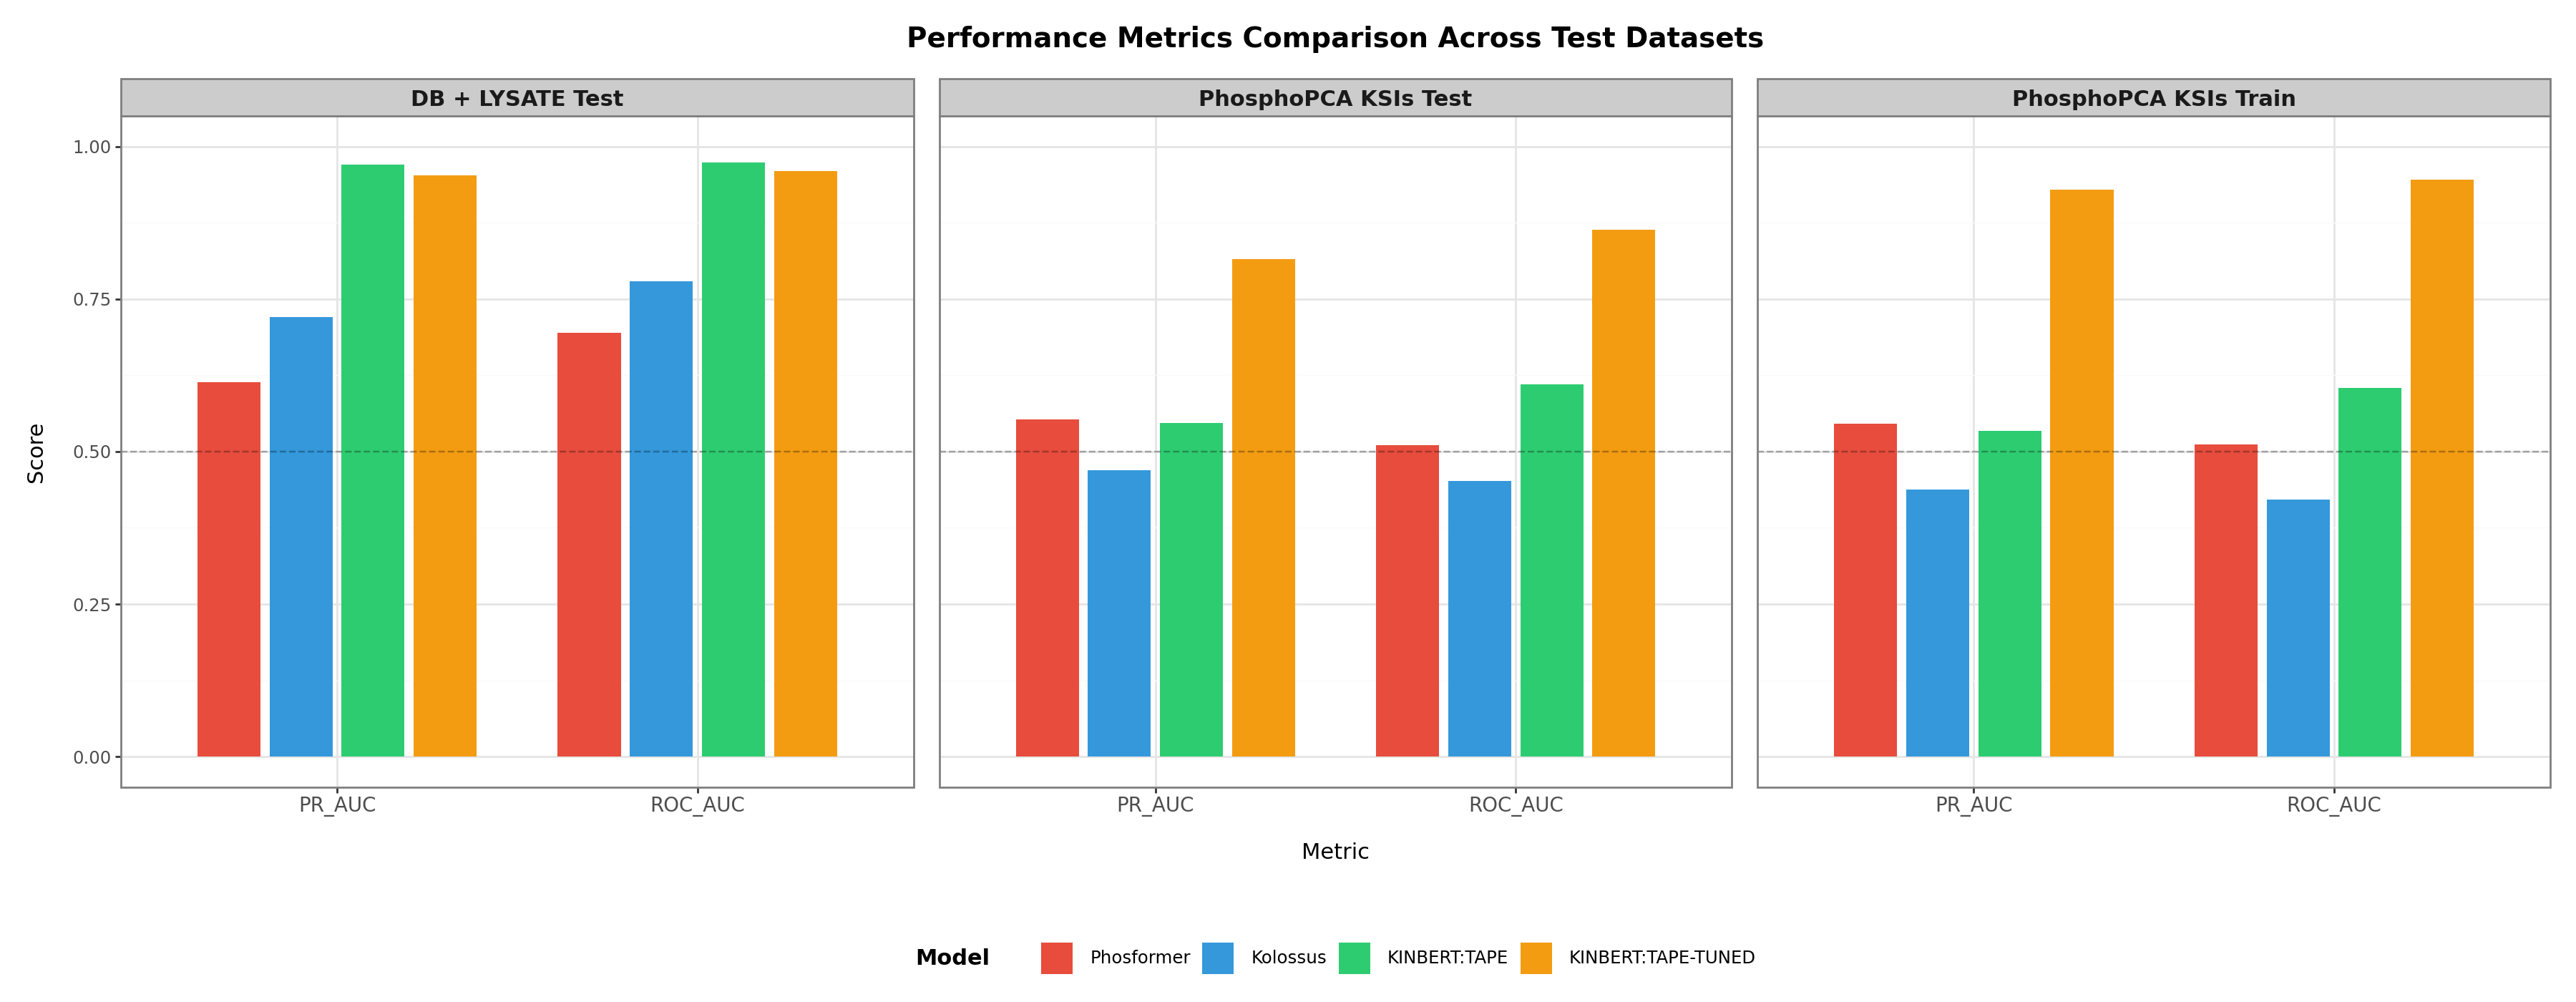

In [36]:
p_bar

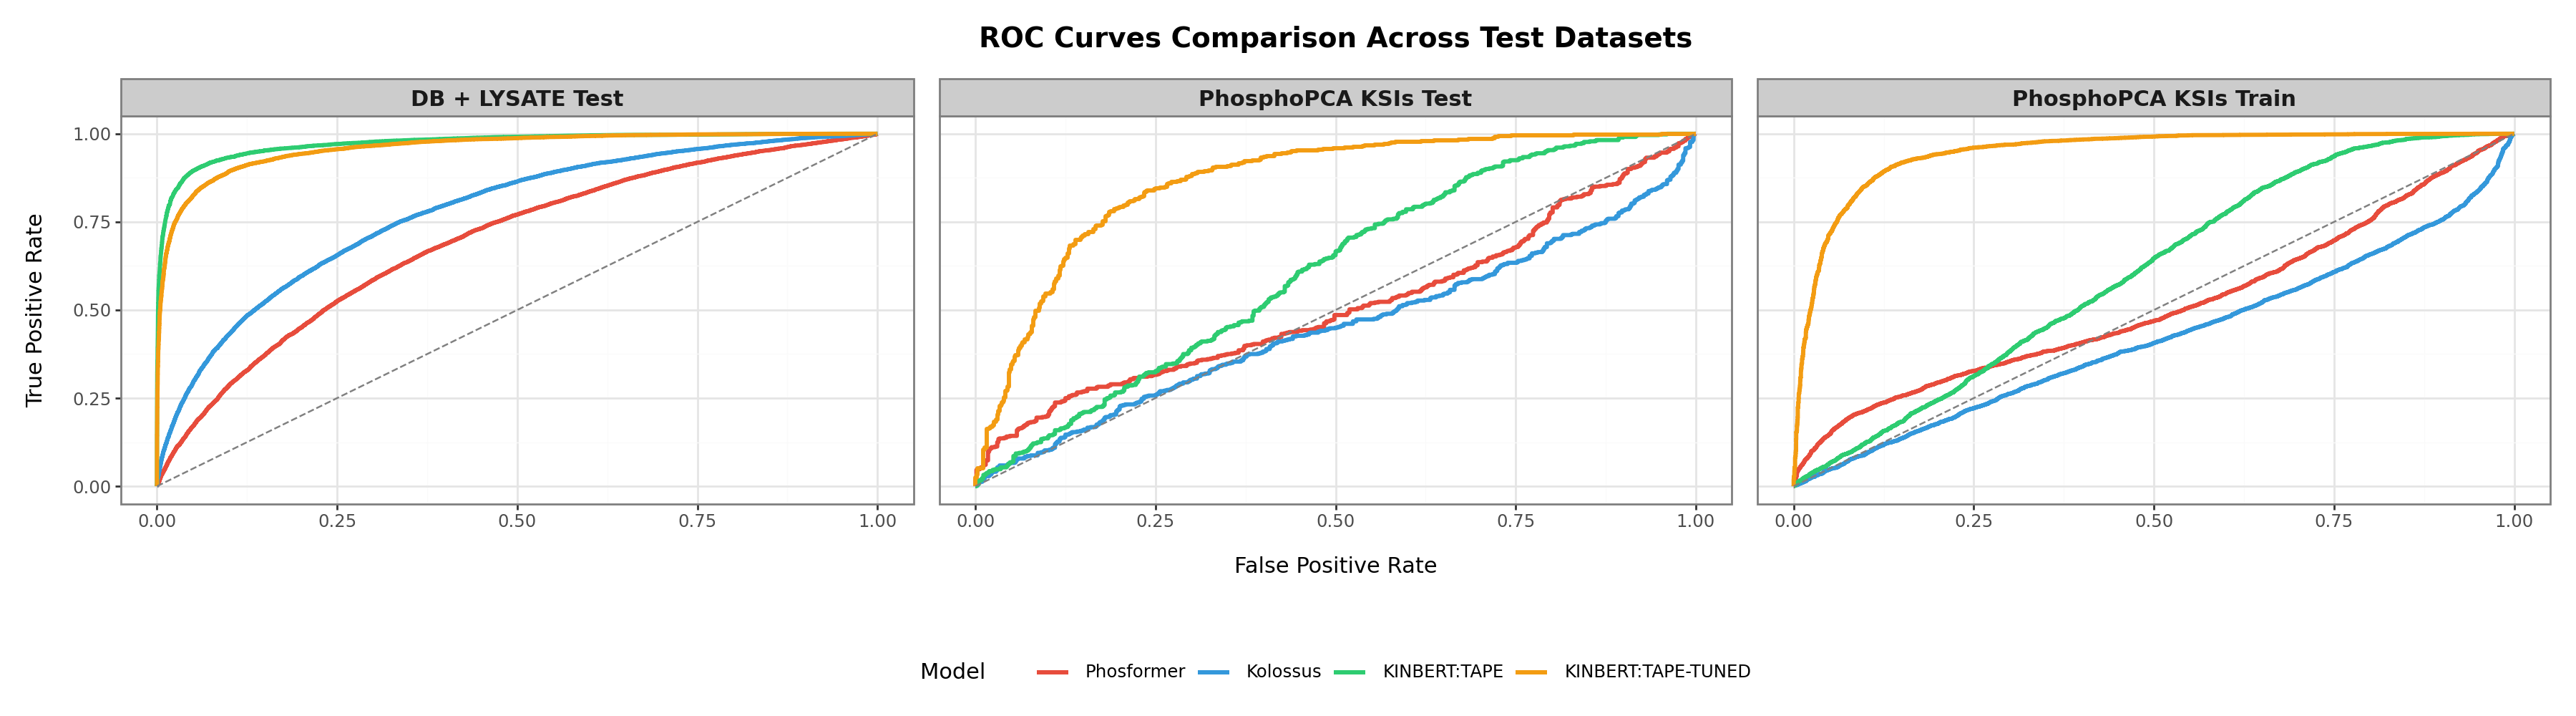

In [37]:
p_roc

In [38]:
out_df = (combined_metrics.loc[:,['Model','Test_Dataset','ROC_AUC','PR_AUC']].set_index(["Test_Dataset", "Model"])[["ROC_AUC", "PR_AUC"]]
    .unstack("Model")          # Model becomes column level
    .sort_index(axis=1, level=0))
out_df = out_df.fillna('')
latex_str = out_df.to_latex(
    multicolumn=True,
    multicolumn_format='c',
    float_format="%.3f",
    index_names=False,
    bold_rows=False,
    escape=False
)
print(latex_str)

\begin{tabular}{lrrrrrrrr}
\toprule
 & \multicolumn{4}{c}{PR_AUC} & \multicolumn{4}{c}{ROC_AUC} \\
Model & Phosformer & Kolossus & KINBERT:TAPE & KINBERT:TAPE-TUNED & Phosformer & Kolossus & KINBERT:TAPE & KINBERT:TAPE-TUNED \\
\midrule
DB + LYSATE Test & 0.614 & 0.720 & 0.970 & 0.953 & 0.695 & 0.779 & 0.973 & 0.960 \\
PhosphoPCA KSIs Test & 0.552 & 0.469 & 0.547 & 0.816 & 0.510 & 0.452 & 0.610 & 0.864 \\
PhosphoPCA KSIs Train & 0.546 & 0.438 & 0.534 & 0.929 & 0.511 & 0.421 & 0.605 & 0.946 \\
\bottomrule
\end{tabular}



In [ ]:
# Display plots
# p_bar.save('./eval_figs/benchmark_generalizability_bar.png')
# p_bar.save('./eval_figs/benchmark_generalizability_bar.pdf')

# p_roc.save('./eval_figs/benchmark_generalizability_roc.png')
# p_roc.save('./eval_figs/benchmark_generalizability_roc.pdf')